<a href="https://colab.research.google.com/github/shriya-dev-ui/lab1aiml/blob/main/Stroke_Prediction_Comparative_Study_p3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stroke Prediction: Machine Learning Model Comparison

**Objective:** Train and compare five supervised learning models on the processed stroke dataset and identify the top three models.

The notebook reports **Accuracy, Precision, Recall, F1-Score, AUC-ROC**, ROC curves, and confusion matrices. It uses one stratified train/test split for a fair comparison.

**Models used**
1. Logistic Regression
2. Random Forest
3. Gradient Boosting
4. Support Vector Machine (SVM)
5. Artificial Neural Network (ANN), implemented as a feed-forward Multi-Layer Perceptron (MLP)

> The dataset is already processed and contains numeric features. This notebook does not repeat encoding or preprocessing that has already been completed.

## 1. Import Libraries

Run this cell first. If a library is missing, uncomment the installation line and run it.

In [1]:
# If required, uncomment and run:
# %pip install -U pandas numpy matplotlib seaborn scikit-learn

import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
from sklearn.utils import resample

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Processed Stroke Dataset

The dataset is named **`stroke_processed_5k.csv`** and is shown in your LAB3 folder.

The cell first checks the exact Windows path you provided. If the notebook kernel cannot access that path, it opens a file-selection dialog (where supported). In Google Colab, it displays the upload button instead.

In [2]:
from pathlib import Path
import importlib.util

# Exact location visible in your File Explorer screenshot
data_path = Path(
    r"C:\Users\satya\OneDrive\Desktop\SEM5\Introduction to AI\LAB\LAB3\stroke_processed_5k.csv"
)

# 1) Try the exact Windows path
if data_path.is_file():
    selected_file = str(data_path)
    print("Dataset found at the specified location.")

# 2) If running in Google Colab, show the upload button
elif importlib.util.find_spec("google.colab") is not None:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError("No file was uploaded.")
    selected_file = next(iter(uploaded))
    print("Uploaded file:", selected_file)

# 3) Otherwise, open a local file picker (works in many desktop Jupyter setups)
else:
    selected_file = None
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        selected_file = filedialog.askopenfilename(
            title="Select stroke_processed_5k.csv",
            filetypes=[("CSV files", "*.csv"), ("All files", "*.*")]
        )
        root.destroy()
    except Exception as e:
        print("File picker could not be opened:", e)

    # 4) Final fallback: enter the full path manually
    if not selected_file:
        selected_file = input(
            "Enter the full path of stroke_processed_5k.csv: "
        ).strip().strip('"')

    if not selected_file or not Path(selected_file).is_file():
        raise FileNotFoundError(
            "Dataset not found. Select stroke_processed_5k.csv from the LAB3 folder "
            "or enter its complete file path."
        )

df = pd.read_csv(selected_file)

print("\\nDataset loaded successfully!")
print("File:", selected_file)
print("Dataset shape:", df.shape)
display(df.head())

Saving stroke_processed_5k.csv to stroke_processed_5k.csv
Uploaded file: stroke_processed_5k.csv
\nDataset loaded successfully!
File: stroke_processed_5k.csv
Dataset shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


## 3. Initial Dataset Inspection

Check the column names, data types, missing values, duplicate rows, and target distribution before training.

In [3]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing values"))

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe().T)

TARGET_COLUMN = "stroke"
if TARGET_COLUMN not in df.columns:
    raise ValueError(
        f"Expected target column '{TARGET_COLUMN}' was not found. "
        f"Available columns: {list(df.columns)}"
    )

print("\nTarget distribution:")
display(df[TARGET_COLUMN].value_counts().rename_axis("stroke").to_frame("Count"))
display((df[TARGET_COLUMN].value_counts(normalize=True) * 100)
        .rename_axis("stroke").to_frame("Percentage"))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 439.3 KB

Missing values in each column:


,Missing values
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0



Number of duplicate rows: 0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
gender,5110.0,4.142857e-01,0.493044,0.000000,0.000000,0.000000,1.000000,2.000000
age,5110.0,4.449583e-17,1.000098,-1.908261,-0.806115,0.078432,0.786070,1.714845
hypertension,5110.0,9.745597e-02,0.296607,0.000000,0.000000,0.000000,0.000000,1.000000
heart_disease,5110.0,5.401174e-02,0.226063,0.000000,0.000000,0.000000,0.000000,1.000000
ever_married,5110.0,6.561644e-01,0.475034,0.000000,0.000000,1.000000,1.000000,1.000000
work_type,5110.0,2.167710e+00,1.090293,0.000000,2.000000,2.000000,3.000000,4.000000
Residence_type,5110.0,5.080235e-01,0.499985,0.000000,0.000000,1.000000,1.000000,1.000000
avg_glucose_level,5110.0,1.168015e-16,1.000098,-1.126958,-0.638322,-0.314995,0.175408,3.657145
bmi,5110.0,-3.893385e-17,1.000098,-2.411027,-0.657509,-0.098981,0.511503,8.928390
smoking_status,5110.0,1.376908e+00,1.071534,0.000000,0.000000,2.000000,2.000000,3.000000



Target distribution:


,Count
stroke,
0,4861
1,249


,Percentage
stroke,
0,95.127202
1,4.872798


## 4. Exploratory Data Analysis (EDA)

The following plots show the class distribution, feature distributions, and feature correlations. The stroke class is usually much smaller than the non-stroke class, so recall and AUC-ROC are important alongside accuracy.

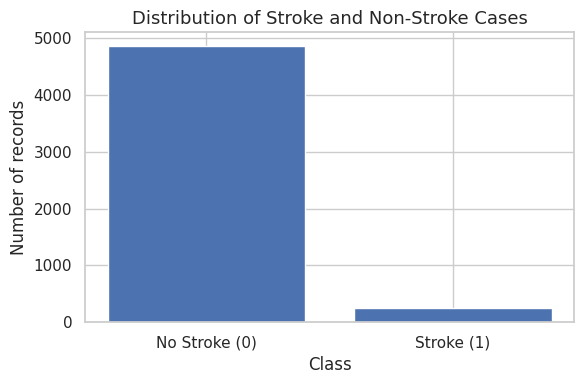

In [4]:
target_counts = df[TARGET_COLUMN].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(["No Stroke (0)", "Stroke (1)"], target_counts.values)
plt.title("Distribution of Stroke and Non-Stroke Cases")
plt.xlabel("Class")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

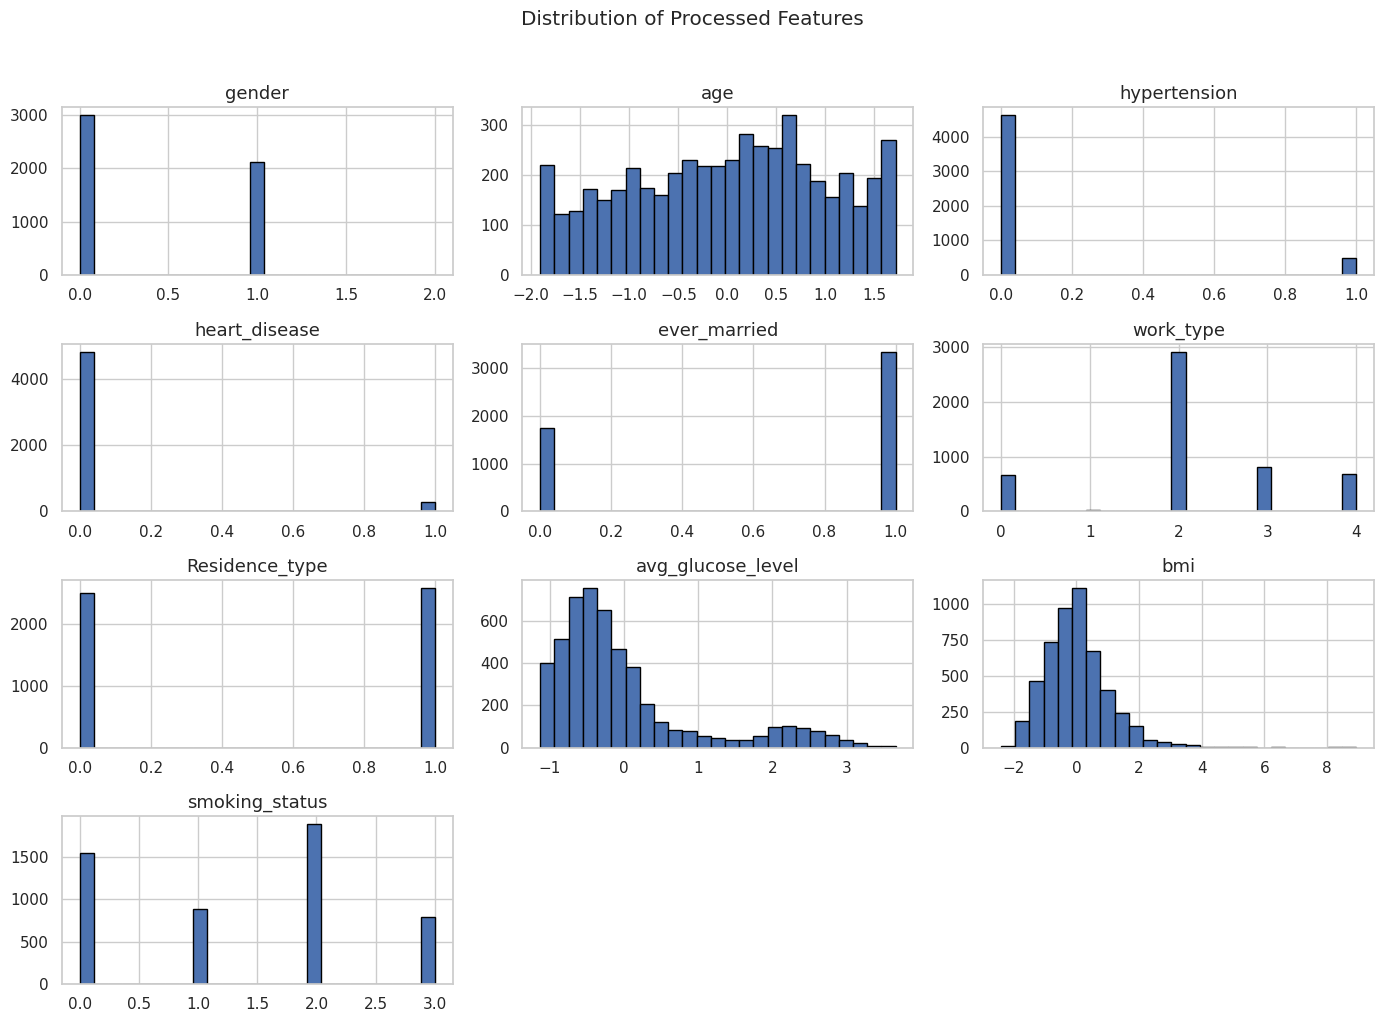

In [5]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
feature_columns_for_plot = [c for c in numeric_columns if c != TARGET_COLUMN]

df[feature_columns_for_plot].hist(
    figsize=(14, 10), bins=25, edgecolor="black"
)
plt.suptitle("Distribution of Processed Features", y=1.02)
plt.tight_layout()
plt.show()

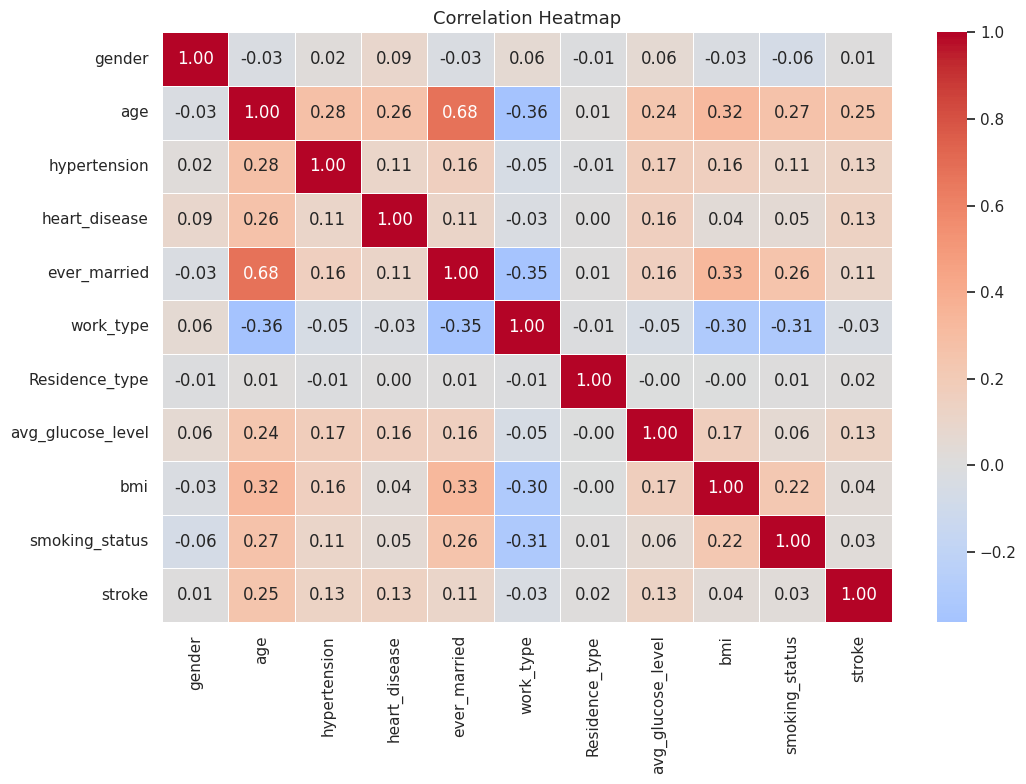

In [6]:
plt.figure(figsize=(11, 8))
sns.heatmap(df[numeric_columns].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=0.4)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 5. Prepare Features and Target

The target variable is `stroke`. All remaining columns are used as input features. The data is split into training and testing sets using stratification so that the stroke/non-stroke proportions are preserved in both sets.

To address class imbalance without contaminating the test set, minority-class oversampling is performed **only on the training data**. The test set remains untouched and retains the original class distribution.

In [7]:
# Separate input features (X) and target (y)
X = df.drop(columns=[TARGET_COLUMN]).copy()
y = df[TARGET_COLUMN].copy()

# Ensure all feature columns are numeric and data is valid
X = X.apply(pd.to_numeric, errors="raise")
if X.isnull().any().any() or y.isnull().any():
    raise ValueError("Missing values detected. Review the dataset before model training.")

classes = sorted(pd.Series(y).unique().tolist())
if classes != [0, 1]:
    raise ValueError(
        f"This notebook expects a binary target encoded as 0 and 1; found {classes}."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining target distribution:")
display(y_train.value_counts().rename("Count").to_frame())
print("\nTesting target distribution:")
display(y_test.value_counts().rename("Count").to_frame())

Training set: (4088, 10)
Testing set: (1022, 10)

Training target distribution:


,Count
stroke,
0,3889
1,199



Testing target distribution:


,Count
stroke,
0,972
1,50


In [8]:
# Oversample only the minority class in the training data.
# The test data is deliberately NOT oversampled.
train_data = X_train.copy()
train_data[TARGET_COLUMN] = y_train.values

class_counts = train_data[TARGET_COLUMN].value_counts()
majority_class = class_counts.idxmax()
minority_class = class_counts.idxmin()

majority_data = train_data[train_data[TARGET_COLUMN] == majority_class]
minority_data = train_data[train_data[TARGET_COLUMN] == minority_class]

minority_oversampled = resample(
    minority_data,
    replace=True,
    n_samples=len(majority_data),
    random_state=RANDOM_STATE
)

train_balanced = pd.concat(
    [majority_data, minority_oversampled],
    axis=0
).sample(frac=1, random_state=RANDOM_STATE)

X_train_balanced = train_balanced.drop(columns=[TARGET_COLUMN])
y_train_balanced = train_balanced[TARGET_COLUMN]

print("Original training class counts:")
display(y_train.value_counts().sort_index().rename("Count").to_frame())

print("Training class counts after oversampling:")
display(y_train_balanced.value_counts().sort_index().rename("Count").to_frame())

Original training class counts:


,Count
stroke,
0,3889
1,199


Training class counts after oversampling:


,Count
stroke,
0,3889
1,3889


In [9]:
# Standardization is used for models sensitive to feature scale.
# Fit the scaler on the balanced training data only; apply the same transform to test data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


## 6. Define the Evaluation Function

Every model is evaluated on the same untouched test set. The function records Accuracy, Precision, Recall, F1-Score, and AUC-ROC, prints the classification report, and plots the confusion matrix.

For stroke prediction, **Recall for class 1** is especially important because it measures how many actual stroke cases are detected. A high accuracy alone can be misleading when the dataset is imbalanced.

In [10]:
results = {}
roc_data = {}
confusion_matrices = {}
trained_models = {}

def evaluate_model(model_name, y_true, y_pred, y_probability):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc_value = roc_auc_score(y_true, y_probability)

    results[model_name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "AUC-ROC": auc_value
    }

    fpr, tpr, thresholds = roc_curve(y_true, y_probability)
    roc_data[model_name] = (fpr, tpr, auc_value)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    confusion_matrices[model_name] = cm

    print(f"========== {model_name} ==========")
    print(classification_report(
        y_true, y_pred,
        labels=[0, 1],
        target_names=["No Stroke", "Stroke"],
        zero_division=0
    ))
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print(f"AUC-ROC  : {auc_value:.4f}")

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No Stroke", "Stroke"],
        yticklabels=["No Stroke", "Stroke"]
    )
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.tight_layout()
    plt.show()

## 7. Model 1 — Logistic Regression

Logistic Regression is a linear classification model and provides a useful baseline for binary prediction.

========== Logistic Regression ==========
              precision    recall  f1-score   support

   No Stroke       0.99      0.74      0.85       972
      Stroke       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022

Accuracy : 0.7466
Precision: 0.1384
Recall   : 0.8000
F1-Score : 0.2360
AUC-ROC  : 0.8390


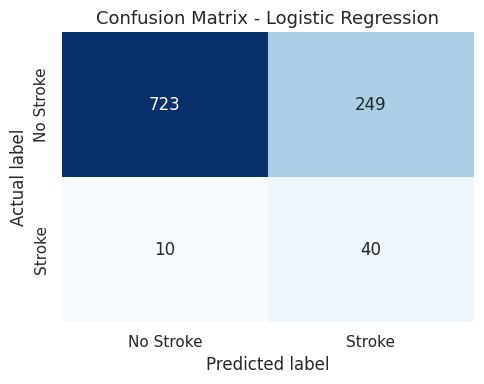

In [11]:
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE
)
logistic_model.fit(X_train_scaled, y_train_balanced)

logistic_pred = logistic_model.predict(X_test_scaled)
logistic_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

trained_models["Logistic Regression"] = logistic_model
evaluate_model("Logistic Regression", y_test, logistic_pred, logistic_prob)

## 8. Model 2 — Random Forest

Random Forest combines multiple decision trees. It can model non-linear relationships and interactions between features.

========== Random Forest ==========
              precision    recall  f1-score   support

   No Stroke       0.96      0.98      0.97       972
      Stroke       0.30      0.14      0.19        50

    accuracy                           0.94      1022
   macro avg       0.63      0.56      0.58      1022
weighted avg       0.93      0.94      0.93      1022

Accuracy : 0.9423
Precision: 0.3043
Recall   : 0.1400
F1-Score : 0.1918
AUC-ROC  : 0.8133


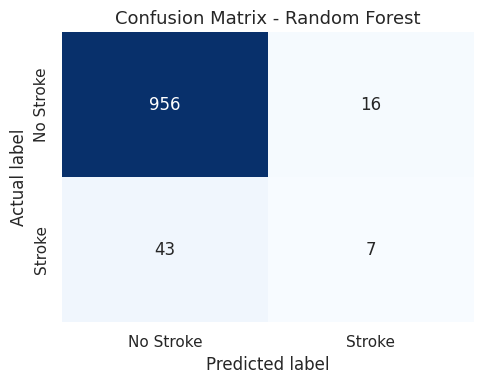

In [12]:
random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    min_samples_leaf=2
)
random_forest_model.fit(X_train_balanced, y_train_balanced)

rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

trained_models["Random Forest"] = random_forest_model
evaluate_model("Random Forest", y_test, rf_pred, rf_prob)

## 9. Model 3 — Gradient Boosting

Gradient Boosting builds trees sequentially, with each new tree focusing on errors made by the preceding ensemble.

========== Gradient Boosting ==========
              precision    recall  f1-score   support

   No Stroke       0.99      0.72      0.83       972
      Stroke       0.13      0.82      0.23        50

    accuracy                           0.73      1022
   macro avg       0.56      0.77      0.53      1022
weighted avg       0.95      0.73      0.81      1022

Accuracy : 0.7280
Precision: 0.1323
Recall   : 0.8200
F1-Score : 0.2278
AUC-ROC  : 0.8458


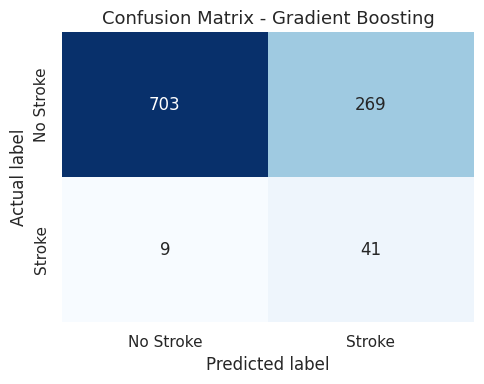

In [13]:
gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    random_state=RANDOM_STATE
)
gradient_boosting_model.fit(X_train_balanced, y_train_balanced)

gb_pred = gradient_boosting_model.predict(X_test)
gb_prob = gradient_boosting_model.predict_proba(X_test)[:, 1]

trained_models["Gradient Boosting"] = gradient_boosting_model
evaluate_model("Gradient Boosting", y_test, gb_pred, gb_prob)

## 10. Model 4 — Support Vector Machine (SVM)

SVM seeks a decision boundary that separates classes. The RBF kernel can represent non-linear decision boundaries. Standardized features are used.

========== SVM ==========
              precision    recall  f1-score   support

   No Stroke       0.97      0.77      0.86       972
      Stroke       0.11      0.56      0.18        50

    accuracy                           0.76      1022
   macro avg       0.54      0.66      0.52      1022
weighted avg       0.93      0.76      0.82      1022

Accuracy : 0.7564
Precision: 0.1098
Recall   : 0.5600
F1-Score : 0.1836
AUC-ROC  : 0.7687


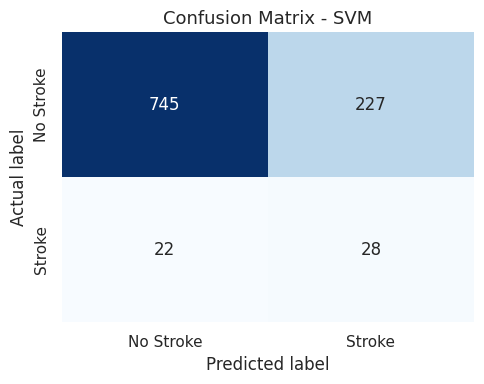

In [14]:
svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=RANDOM_STATE
)
svm_model.fit(X_train_scaled, y_train_balanced)

svm_pred = svm_model.predict(X_test_scaled)
svm_prob = svm_model.predict_proba(X_test_scaled)[:, 1]

trained_models["SVM"] = svm_model
evaluate_model("SVM", y_test, svm_pred, svm_prob)

## 11. Model 5 — Artificial Neural Network (ANN)

The ANN is implemented using `MLPClassifier`, a feed-forward neural network with two hidden layers. It is trained on standardized features.

========== ANN ==========
              precision    recall  f1-score   support

   No Stroke       0.95      0.93      0.94       972
      Stroke       0.09      0.14      0.11        50

    accuracy                           0.89      1022
   macro avg       0.52      0.54      0.53      1022
weighted avg       0.91      0.89      0.90      1022

Accuracy : 0.8924
Precision: 0.0946
Recall   : 0.1400
F1-Score : 0.1129
AUC-ROC  : 0.7471


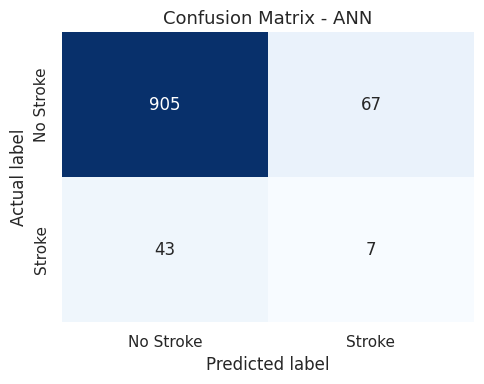

In [15]:
ann_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0005,
    learning_rate_init=0.001,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.10,
    n_iter_no_change=20,
    random_state=RANDOM_STATE
)
ann_model.fit(X_train_scaled, y_train_balanced)

ann_pred = ann_model.predict(X_test_scaled)
ann_prob = ann_model.predict_proba(X_test_scaled)[:, 1]

trained_models["ANN"] = ann_model
evaluate_model("ANN", y_test, ann_pred, ann_prob)

## 12. Combined ROC Curve Comparison

The ROC curve compares the true-positive rate with the false-positive rate across classification thresholds. AUC-ROC summarizes the ranking ability of each model; higher values indicate better separation of the two classes.

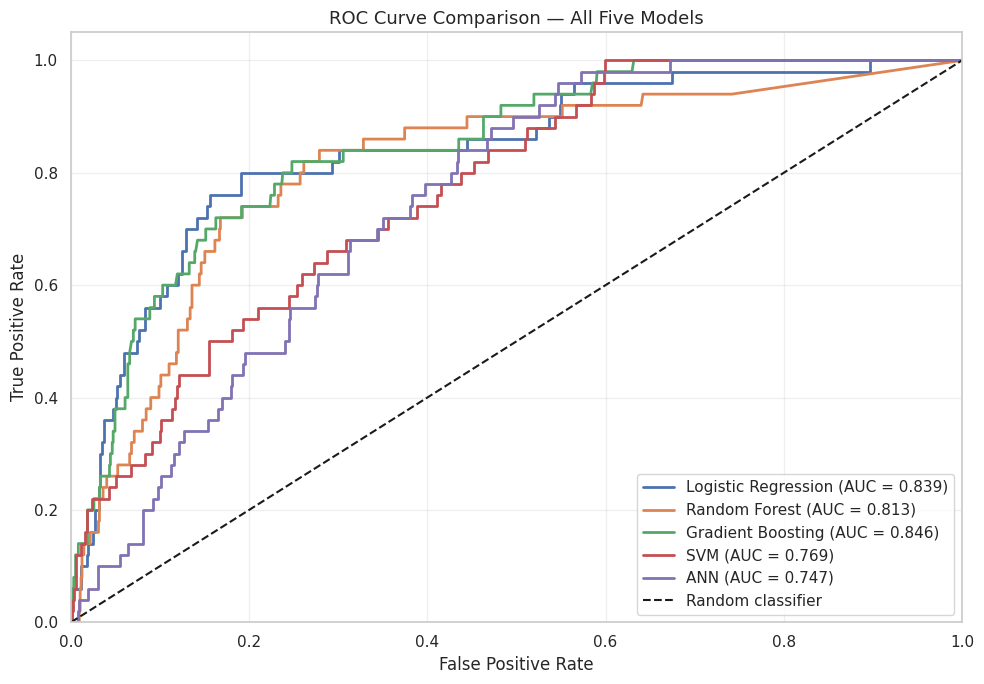

In [16]:
plt.figure(figsize=(10, 7))
for model_name, (fpr, tpr, auc_value) in roc_data.items():
    plt.plot(fpr, tpr, linewidth=2,
             label=f"{model_name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison — All Five Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 13. Overall Performance Comparison and Top 3 Models

The five models are ranked by **AUC-ROC** to compare their ability to distinguish stroke and non-stroke cases across thresholds. The full metric table is also displayed so the ranking can be interpreted alongside Precision, Recall, F1-Score, and Accuracy.

In [17]:
metrics_df = pd.DataFrame(results).T
metrics_df = metrics_df.sort_values(by="AUC-ROC", ascending=False)

print("Performance comparison of all five models:")
display(metrics_df.style.format("{:.4f}"))

top_3 = metrics_df.head(3)
top_3_names = top_3.index.tolist()

print("Top 3 models ranked by AUC-ROC:")
display(top_3.style.format("{:.4f}"))

print("Top model:", top_3_names[0])

Performance comparison of all five models:


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Gradient Boosting,0.7280,0.1323,0.8200,0.2278,0.8458
Logistic Regression,0.7466,0.1384,0.8000,0.2360,0.8390
Random Forest,0.9423,0.3043,0.1400,0.1918,0.8133
SVM,0.7564,0.1098,0.5600,0.1836,0.7687
ANN,0.8924,0.0946,0.1400,0.1129,0.7471


Top 3 models ranked by AUC-ROC:


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Gradient Boosting,0.7280,0.1323,0.8200,0.2278,0.8458
Logistic Regression,0.7466,0.1384,0.8000,0.2360,0.8390
Random Forest,0.9423,0.3043,0.1400,0.1918,0.8133


Top model: Gradient Boosting


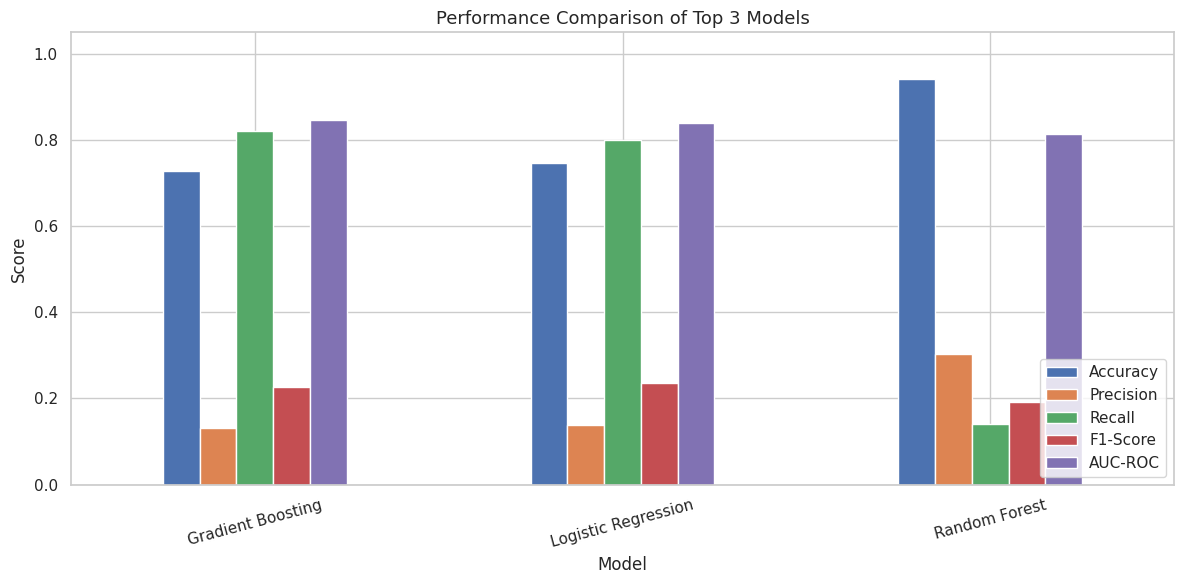

In [18]:
# Compare the five evaluation metrics for the selected top three models.
top_3[["Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"]].plot(
    kind="bar", figsize=(12, 6)
)
plt.title("Performance Comparison of Top 3 Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

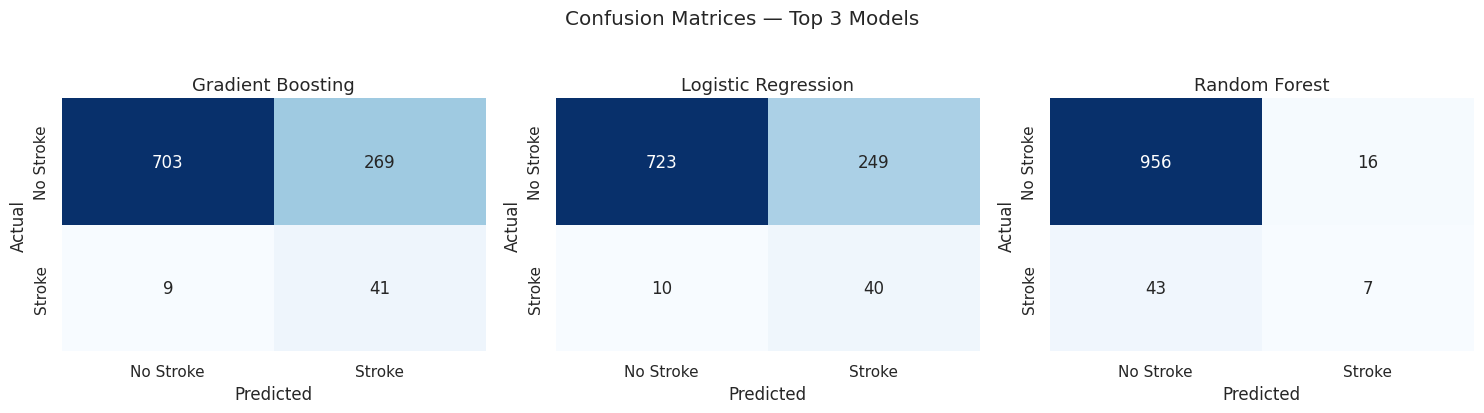

In [19]:
# Confusion matrices for the top three models
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, model_name in zip(axes, top_3_names):
    sns.heatmap(
        confusion_matrices[model_name],
        annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["No Stroke", "Stroke"],
        yticklabels=["No Stroke", "Stroke"]
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Confusion Matrices — Top 3 Models", y=1.03)
plt.tight_layout()
plt.show()

## 14. Final Comparative Summary

Use the generated results below to write the conclusion. The notebook deliberately does not hard-code a winning model: the top three are selected from the actual test-set AUC-ROC values after execution.

In [20]:
best_model_name = metrics_df.index[0]
best_model_metrics = metrics_df.iloc[0]

print("FINAL RESULT")
print("-" * 50)
print("Best model based on AUC-ROC:", best_model_name)
print(f"Accuracy : {best_model_metrics['Accuracy']:.4f}")
print(f"Precision: {best_model_metrics['Precision']:.4f}")
print(f"Recall   : {best_model_metrics['Recall']:.4f}")
print(f"F1-Score : {best_model_metrics['F1-Score']:.4f}")
print(f"AUC-ROC  : {best_model_metrics['AUC-ROC']:.4f}")

print("\nTop 3 models:")
for rank, model_name in enumerate(top_3_names, start=1):
    print(f"{rank}. {model_name} — AUC-ROC: {metrics_df.loc[model_name, 'AUC-ROC']:.4f}")

print("\nInterpretation reminder:")
print(
    "Compare recall for the stroke class and the confusion matrices as well as "
    "AUC-ROC. A model with high accuracy may still miss stroke cases."
)

FINAL RESULT
--------------------------------------------------
Best model based on AUC-ROC: Gradient Boosting
Accuracy : 0.7280
Precision: 0.1323
Recall   : 0.8200
F1-Score : 0.2278
AUC-ROC  : 0.8458

Top 3 models:
1. Gradient Boosting — AUC-ROC: 0.8458
2. Logistic Regression — AUC-ROC: 0.8390
3. Random Forest — AUC-ROC: 0.8133

Interpretation reminder:
Compare recall for the stroke class and the confusion matrices as well as AUC-ROC. A model with high accuracy may still miss stroke cases.


## 15. Conclusion

After running all cells, complete the conclusion using the values produced in the performance comparison table.

Discuss:
- Which model achieved the highest AUC-ROC?
- Which model achieved the highest recall for stroke cases?
- How do the precision and F1-score compare among the top three models?
- What do the confusion matrices reveal about false negatives and false positives?

**Important:** This is an academic machine-learning exercise using a processed dataset. Its predictions are not a medical diagnosis or a clinically validated stroke-risk assessment.